**本篇关于卷积神经网络的代码实现**

In [17]:
import torch
from torch import nn
from d2l import torch as d2l

## 卷积的实现

In [18]:
#定义一个用于计算二维卷积（实际上是交叉相关）的函数
#X 代表了输入矩阵，G 是卷积核
def corr2d(X, G):
    Y = torch.zeros_like(X.shape[0] - G.shape[0] + 1, 
                         X.shape[1] - G.shape[1] + 1)
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            Y[i][j] = (X[i : i + G.shape[0], j : j + G.shape[1]] * G).sum()
    return Y

In [19]:
#一个二维卷积层
class Conv2D(nn.Module):
    #kernel_size 卷积核的大小
    def __init__(self, kernel_size):
        super().__init__()
        self.weight = nn.Parameter(torch.rand(kernel_size))
        self.bias = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        #返回卷积结果加上偏置
        return corr2d(x, self.weight) + self.bias

## 卷积神经网络的架构
> **由于卷积神经网络的计算成本较高，以下通过colab采用GPU来加快训练而非在CPU上完成**

### 模型

In [20]:
#卷积神经网络模型结构
net = nn.Sequential(
    #卷积层: batch_size, out_channel, kernel_size (卷积核大小), padding (边缘填充)
    nn.Conv2d(1, 6, kernel_size=5, padding=2), 
    #激活函数（请注意，虽然ReLU和最大汇聚层更有效，但它们在20世纪90年代还没有出现）
    nn.Sigmoid(),
    #这里先激活再池化，先对单个元素做非线性变化，保留特征
    #汇聚层（池化层）: kernel_size (滑动窗口), stride (步长)
    nn.AvgPool2d(kernel_size=2, stride=2),
    #卷积层
    nn.Conv2d(6, 16, kernel_size=5), 
    nn.Sigmoid(),
    #池化层
    nn.AvgPool2d(kernel_size=2, stride=2),
    #由于线性层的输入是 n * 1 的，所以要把池化结果展平
    #下方就是一个多层感知机
    nn.Flatten(),
    nn.Linear(16 * 5 * 5, 120), 
    nn.Sigmoid(),
    nn.Linear(120, 84), 
    nn.Sigmoid(),
    nn.Linear(84, 10)
)

In [21]:
#参数初始化
def init_weights(m):
    if type(m) == nn.Linear or type(m) == nn.Conv2d:
        #这里采用 xavier 的方法初始化参数，减少反向传播时梯度爆炸和梯度消失的影响
        nn.init.xavier_uniform_(m.weight)
net.apply(init_weights)

Sequential(
  (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (1): Sigmoid()
  (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (4): Sigmoid()
  (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=400, out_features=120, bias=True)
  (8): Sigmoid()
  (9): Linear(in_features=120, out_features=84, bias=True)
  (10): Sigmoid()
  (11): Linear(in_features=84, out_features=10, bias=True)
)

### 前置函数
> **由于此处是在GPU里进行神经网络的训练，所以需要特制相关函数**

In [22]:
#在GPU里计算评估模型准确率
def evaluate_accuracy_gpu(net, data_iter, device_GPU = None):
    if isinstance(net, nn.Module):
        net.eval()
        if not device_GPU:
            #如果模型参数没有被加载到GPU中，那么先加载
            device_GPU = next(iter(net.parameters())).device
    metric = d2l.Accumulator(2)
    with torch.no_grad():
        for X, y in data_iter:
            if isinstance(X, list):
                # BERT微调所需的（之后将介绍）
                X = [x.to(device_GPU) for x in X]
            else:
                X = X.to(device_GPU)
            y = y.to(device_GPU)
            metric.add(d2l.accuracy(net(X), y), y.numel())
    return metric[0] / metric[1]


In [23]:
def train_ch6(net, train_iter, test_iter, num_epochs, loss, updater, device):
    animator = d2l.Animator(xlabel='epoch', xlim=[1, num_epochs], legend=['train loss', 'train acc', 'test acc'])
    #计时器，用于记录训练时间
    timer = d2l.Timer()
    #总共有多少批样本
    num_batches = len(train_iter)

    for epoch in range(num_epochs):
        #用于记录 损失之和、准确率之和、样本数
        metric = d2l.Accumulator(3)
        #调整为训练模式
        net.train()
        for i, (X, y) in enumerate(train_iter):
            timer.start()

            #梯度清零
            updater.zero_grad()
            #把训练数据加载到GPU中
            X, y = X.to(device), y.to(device)
            pred_y = net(X)
            loss_ = loss(pred_y, y)
            loss_.backward()
            updater.step()
            #开始记录误差
            with torch.no_grad():
                metric.add(loss_ * X.shape[0], d2l.accuracy(pred_y, y), X.shape[0])
            
            timer.stop()

            train_loss = metric[0] / metric[2]
            train_acc = metric[1] / metric[2]
            if (i + 1) % (num_batches // 5) == 0 or i == num_batches - 1:
                animator.add(epoch + (i + 1) / num_batches, (train_loss, train_acc, None))
        test_acc = evaluate_accuracy_gpu(net, test_iter)
        animator.add(epoch + 1, (None, None, test_acc))
    print(f'loss {train_loss:.3f}, train acc {train_acc:.3f}, '
          f'test acc {test_acc:.3f}')
    print(f'{metric[2] * num_epochs / timer.sum():.1f} examples/sec '
          f'on {str(device)}')

### 模型训练

In [24]:
#超参数
batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size=batch_size)
lr = 0.9
num_epoch = 10
loss = nn.CrossEntropyLoss()
device = d2l.try_gpu()
net.to(device)
updater = torch.optim.SGD(net.parameters(), lr = lr)

loss 0.468, train acc 0.823, test acc 0.783
22836.8 examples/sec on cpu


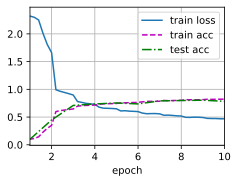

In [25]:
train_ch6(net, train_iter, test_iter, num_epoch, loss, updater, device)